# Figure 2: distinct inflammatory patterns in chromatin accessibility and gene expression in the LPC-lesioned mouse brain

Mouse brain 10 days after a lysolecithin (LPC) injection, one section profiled by DBiT ARC-seq (GEO GSM9247593 for RNA,
GSM9249009 for ATAC; 8,180 spots) and a CODEX scan of an adjacent section. Saturn is fitted on a field of view of 3,425 spots that
holds the injection lesion and a distal white-matter focus of microglia. The figure shows the CODEX image with the field of view (b), the fit quality
(c), the axes and their domains (d), where the two lesions sit on each axis (e), feature functions along each axis (f-i),
inflammatory genes on both axes (j), TF activity along rho_ATAC (k, l) and cis gene-peak concordance against SEACells metacells (m, n).

Conda env `spatialmultivelo` (with `snapatac2`, `pyjaspar`, `pyfaidx`, `tifffile`). About 15 min on a CPU, 6 min of it the
Saturn fit with 8 threads.

## Setup

A CPU fit depends on the seed and on the thread count, so `OMP_NUM_THREADS` is set before `numpy` and `torch` are imported. This fit
uses 8 threads. Inputs are read from `WORK`; results of tools that run outside this kernel sit in `WORK/published`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "8"

import json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import snapatac2 as snap
import tifffile
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon, Rectangle, ConnectionPatch
from matplotlib.offsetbox import TextArea, HPacker, AnchoredOffsetbox
from scipy.spatial import cKDTree, ConvexHull
from scipy.sparse.csgraph import connected_components
from scipy.stats import mannwhitneyu, wilcoxon, spearmanr, chi2_contingency

import saturn
from saturn.theme import MODALITY, DOMAIN, REGION, LINEAGE, CMAP, ANCHOR, SATURN

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig2"
OUT.mkdir(parents=True, exist_ok=True)
saturn.theme.set_theme(7)

C_RNA, C_ATAC, INK, GRID = MODALITY["RNA"], MODALITY["ATAC"], ANCHOR["ink"], ANCHOR["stone"]
pw = saturn.piecewise

## Fig. 2a: experimental design

Fig. 2a is a schematic of the experiment (LPC injection into the corpus callosum, brains collected 10 days later, adjacent
sections profiled by DBiT ARC-seq and CODEX); it is not drawn here.

## Data

RNA and ATAC AnnData of the section, built from the GEO files: RNA keeps in-tissue spots and genes seen in at least 10 spots, ATAC
counts fragments on the ENCODE mouse cCREs (paired insertions) and keeps peaks seen in at least 1% of barcodes; both keep the spots
they share.

In [2]:
rna = ad.read_h5ad(WORK / "arcseq_LPC10S1_rna_adata.h5ad")
atac = ad.read_h5ad(WORK / "arcseq_LPC10S1_atac_adata.h5ad")
print("RNA", rna.shape, " ATAC", atac.shape)

RNA (8180, 15799)  ATAC (8180, 68021)


## Choosing the field of view

Microglia are scored on the DBiT RNA (Itgax, Itgam, Cd68, Trem2, Aif1, Cx3cr1, P2ry12), pooled over each spot's 13 nearest spots as a
Poisson z against the section-wide rate. Spots with z > 3 outside the cortex are grouped into connected components on a 6-nearest-
neighbour graph; the largest piece of the two largest components is the lesion and the distal white-matter focus. The cortex is
CellCharter clusters 1, 5 and 2 at K = 10 (CellCharter on scVI, env `tutorial_lpc`, GPU; read from `published/`). The field of view
is the joint bounding box of the two foci, padded by 3 spot pitches, minus the cortex.

In [3]:
xy_all = np.asarray(rna.obsm["spatial"], float)
X_all = sp.csr_matrix(rna.X)
vn = rna.var_names.astype(str)
lib_all = np.asarray(X_all.sum(1)).ravel().clip(1)

def score(genes):
    return np.asarray(X_all[:, vn.get_indexer([g for g in genes if g in vn])].sum(1)).ravel().astype(float)

mg, my = score(["Itgax", "Itgam", "Cd68", "Trem2", "Aif1", "Cx3cr1", "P2ry12"]), score(["Mbp", "Plp1", "Mog"])
nb = cKDTree(xy_all).query(xy_all, k=13)[1]
rate = mg.sum() / lib_all.sum()
zmg = (mg[nb].sum(1) - rate * lib_all[nb].sum(1)) / np.sqrt(np.maximum(rate * lib_all[nb].sum(1), 1e-9))
myz = np.log1p(my / lib_all * 1e4); myz = (myz - myz.mean()) / myz.std()

cc = pd.read_csv(PUB / "LPC10_cc_labels.csv", index_col=0)["cc_K10"].astype(int).values
cc_all = cc[cKDTree(np.load(PUB / "LPC10_coords.npy")).query(xy_all, k=1)[1]]
cortex = np.isin(cc_all, [1, 5, 2])

def components(idx):
    """connected components of the spots idx on a 6-nearest-neighbour graph, largest first"""
    knn = cKDTree(xy_all[idx]).query(xy_all[idx], k=7)[1]
    adj = sp.csr_matrix((np.ones(knn[:, 1:].size), (np.repeat(np.arange(len(idx)), 6), knn[:, 1:].ravel())), shape=(len(idx), len(idx)))
    cl = connected_components(adj + adj.T, directed=False)[1]
    return [idx[cl == k] for k in np.argsort(-np.bincount(cl))]

comp = components(np.where((zmg > 3) & ~cortex)[0])
lesion, distal = components(comp[0])[0], components(comp[1])[0]

pitch = np.median(np.diff(np.unique(xy_all[:, 0])))
foci = np.r_[lesion, distal]
lo, hi = xy_all[foci].min(0) - 3 * pitch, xy_all[foci].max(0) + 3 * pitch
idx = np.where(np.all((xy_all >= lo) & (xy_all <= hi), axis=1) & ~cortex)[0]

xy = xy_all[idx]
bc = rna.obs_names[idx].astype(str)
region = np.where(np.isin(idx, lesion), "lesion", np.where(np.isin(idx, distal), "distal WM focus", "other"))
micro, myelin = zmg[idx], myz[idx]
print("field of view", len(idx), "spots;", pd.Series(region).value_counts().to_dict())

field of view 3425 spots; {'other': 2654, 'lesion': 560, 'distal WM focus': 211}


## Saturn targets

**RNA.** Poisson GLM-PCA with 10 factors over 3,000 Pearson-residual HVGs of these spots (`saturn.rna_glmpc_real`). GLM-PCA starts
from an unseeded random draw, so a new run returns different factors and a different fit; the RNA target of the paper is read from
`published/`. The depth is the count over genes detected in at least 1% of the spots.

**ATAC.** 5 kb tiles from the fragments of these spots, SnapATAC2 spectral embedding with 15 components, component 1 (depth) dropped
(`saturn.atac_spectral`).

In [4]:
X = sp.csr_matrix(rna.X)[idx]
genes = np.array(rna.var_names.astype(str))
Y_R = np.load(PUB / "targets_lpc10_fov.npz", allow_pickle=True)["Y_RNA"]
det = np.asarray((X > 0).sum(0)).ravel() / X.shape[0]
depth_R = np.asarray(X[:, det >= 0.01].sum(1)).ravel()

tmp = OUT / "fov_tiles.h5ad"
data = snap.pp.import_fragments(str(WORK / "GSM9249009_07_LPC10S1_atac_fragments.tsv.gz"), chrom_sizes=snap.genome.mm10,
                                file=str(tmp), sorted_by_barcode=False, min_num_fragments=0, whitelist=set(bc) | {f"{b}-1" for b in bc})
snap.pp.add_tile_matrix(data, bin_size=5000)
tiles = data.to_memory(); data.close(); os.remove(tmp)
tiles.obs_names = [str(b)[:-2] if str(b).endswith("-1") else str(b) for b in tiles.obs_names]
tiles = tiles[list(bc)].copy()
Y_A, info_A = saturn.atac_spectral(tiles, n_comps=15)
Y_A = Y_A.astype(np.float32)
depth_A = info_A["depth"].astype(np.float32)
del tiles

coords_z = saturn.zscore_coords(xy)
print("RNA target", Y_R.shape, " ATAC target", Y_A.shape, " |Spearman| of the dropped component with depth",
      np.round(info_A["depth_corr_dropped"], 2).tolist())

RNA target (3425, 10)  ATAC target (3425, 7)  |Spearman| of the dropped component with depth [0.99]


## Saturn fit

Seed 42, 8 threads, the default training settings. The fit is saved to `OUT/fit` and reused on a rerun. The axes are kept as a
float64 text file and read back from it.

In [5]:
targets, modalities = [Y_R, Y_A], ["RNA", "ATAC"]
FIT = OUT / "fit"
if not (FIT / "axes_float64.csv").exists():
    res = saturn.fit(targets, coords_z, modalities, seeds=[42], threads=8, depth=dict(RNA=depth_R, ATAC=depth_A))
    res.save(FIT, coords=xy, barcodes=list(bc))
    pd.DataFrame(np.c_[xy, res.axes], columns=["x", "y", "d_RNA", "d_ATAC"], index=bc).to_csv(FIT / "axes_float64.csv")
model = saturn.load_model(FIT / "saturn_best.pt", [Y_R.shape[1], Y_A.shape[1]])
axes = pd.read_csv(FIT / "axes_float64.csv", index_col=0)
d_R, d_A = axes.d_RNA.values, axes.d_ATAC.values
D = {"RNA": d_R, "ATAC": d_A}
r2 = saturn.r2_split(model, coords_z, targets, modalities=modalities)
print(pd.DataFrame(r2).T.round(3))
print(f"Pearson r of rho_RNA and rho_ATAC {np.corrcoef(d_R, d_A)[0, 1]:.3f}")

       full  own_axis_only  other_axes_only
RNA   0.643          0.365            0.338
ATAC  0.674          0.498            0.209
Pearson r of rho_RNA and rho_ATAC -0.252


## Fig. 2b: CODEX image with the registered DBiT field of view

CODEX channels CD11c, MBP and DAPI at pyramid level 3, each scaled to its 1st to 99.7th percentile and drawn as a stain on white.
The DBiT spots are placed on CODEX by Catalign (env `catalign`, registration through white-matter images; read from `published/`).
Left: the whole section with the outline of the field of view; right: the enlarged view with the spots of the injection lesion and
the distal white-matter (WM) focus.

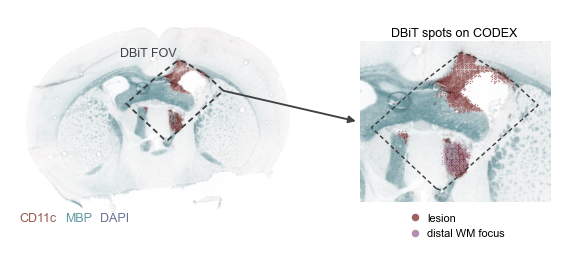

In [6]:
names = json.load(open(WORK / "channels_LPC10_S1.json"))
L3 = tifffile.TiffFile(WORK / "Codex_LPC10_S1.qptiff").series[0].levels[3].asarray()

def norm(a, lo, hi, nonzero=False):
    a = a.astype(float); l, h = np.percentile(a[a > 0] if nonzero else a, [lo, hi])
    return np.clip((a - l) / max(h - l, 1e-9), 0, 1)

STAINS = [("CD11c", ANCHOR["rust"], 1.0), ("MBP", ANCHOR["teal"], 0.8), ("DAPI", ANCHOR["slate"], 0.3)]
ch = {k: norm(L3[names.index(k)], 1, 99.7) for k, _, _ in STAINS}
del L3
rgb = np.clip(1 - sum(norm(ch[k], 1, 99.6, True)[..., None] * (1 - np.array(to_rgb(c))) * g for k, c, g in STAINS), 0, 1)

reg_csv = pd.read_csv(PUB / "LPC10S1_spots_in_codex.csv", index_col=0).loc[bc]
xy_cx = np.c_[reg_csv.codex_lvl0_x.values, reg_csv.codex_lvl0_y.values] / 8      # level-0 pixels -> level 3
hull = xy_cx[ConvexHull(xy_cx).vertices]

fig, (a0, a1) = plt.subplots(1, 2, figsize=(4.6, 2.0), gridspec_kw=dict(width_ratios=[1.5, 1], wspace=0.25))
a0.imshow(rgb[::2, ::2], interpolation="bilinear")
a0.add_patch(Polygon(hull / 2, closed=True, fill=False, ec=INK, lw=0.9, ls=(0, (3, 2))))
top = hull[np.argmin(hull[:, 1])] / 2
a0.text(top[0] - 8, top[1] - 4, "DBiT FOV", color=INK, fontsize=6, va="bottom", ha="right")
keys = HPacker(children=[TextArea(k, textprops=dict(color=c, fontsize=6)) for k, c, _ in STAINS], align="baseline", pad=0, sep=4)
a0.add_artist(AnchoredOffsetbox(loc="lower left", child=keys, frameon=False, pad=0.15, borderpad=0.2))

pad = 60
x0, y0 = (hull.min(0) - pad).astype(int); x1, y1 = (hull.max(0) + pad).astype(int)
a1.imshow(rgb[y0:y1, x0:x1], extent=(x0, x1, y1, y0), interpolation="bilinear")
for r_ in ("lesion", "distal WM focus"):
    m = region == r_
    a1.scatter(xy_cx[m, 0], xy_cx[m, 1], s=0.5, lw=0, color=REGION[r_], alpha=0.75, rasterized=True)
a1.add_patch(Polygon(hull, closed=True, fill=False, ec=INK, lw=0.7, ls=(0, (3, 2))))
a1.set_xlim(x0, x1); a1.set_ylim(y1, y0)
a1.set_title("DBiT spots on CODEX", fontsize=6, pad=2)
a1.legend(handles=[Line2D([], [], ls="", marker="o", ms=2.6, color=REGION[r]) for r in ("lesion", "distal WM focus")],
          labels=["lesion", "distal WM focus"], fontsize=5.3, loc="upper center", bbox_to_anchor=(0.5, -0.01), handletextpad=0.1)
for a in (a0, a1):
    a.set_xticks([]); a.set_yticks([]); [s.set_visible(False) for s in a.spines.values()]
tip = hull[np.argmax(hull[:, 0])] / 2
fig.add_artist(ConnectionPatch(xyA=tip, coordsA=a0.transData, xyB=(-0.02, 0.5), coordsB=a1.transAxes,
                               arrowstyle="-|>", mutation_scale=7, lw=0.9, color=INK))
plt.show()

## Fig. 2c: variance explained

R² of the RNA and ATAC targets by the full model, by the own axis alone (cross term held at its mean) and by the cross axis
alone (n = 3,425 spots).

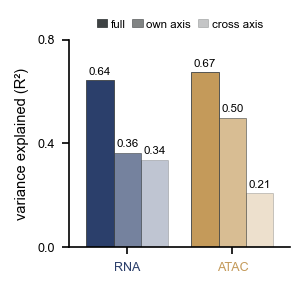

In [7]:
fig, ax = plt.subplots(figsize=(1.9, 1.8))
xb, w = np.arange(2), 0.26
for i, (key, alpha) in enumerate([("full", 1.0), ("own_axis_only", 0.65), ("other_axes_only", 0.3)]):
    v = [r2[m][key] for m in modalities]
    ax.bar(xb + (i - 1) * w, v, w, color=[MODALITY[m] for m in modalities], alpha=alpha, edgecolor=INK, lw=0.4)
    for xx, vv in zip(xb + (i - 1) * w, v):
        ax.text(xx, vv + 0.015, f"{vv:.2f}", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks(xb); ax.set_xticklabels(modalities)
for tl, m in zip(ax.get_xticklabels(), modalities):
    tl.set_color(MODALITY[m])
ax.set_ylim(0, 0.8); ax.set_yticks([0, 0.4, 0.8]); ax.set_ylabel("variance explained (R²)"); ax.set_xlim(-0.55, 1.55)
ax.legend(handles=[Patch(fc=INK, alpha=a_, ec=INK, lw=0.4, label=l_) for a_, l_ in [(1, "full"), (0.65, "own axis"), (0.3, "cross axis")]],
          fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=0.9, columnspacing=0.6, handletextpad=0.3)
plt.show()

## Domains along each axis

Each axis is segmented with its own target by GASTON's dynamic programme (`saturn.domains.gaston_domains`), with K at the elbow of
the error curve (`choose_k`). The domains are named from their composition: on rho_RNA, the domain with the most lesion spots is the
lesion core, the one with the highest myelin score is white matter, and the remaining microglia-poor domain is thalamic &
periventricular; on rho_ATAC, the domain with the highest microglia score holds spots from both foci and is the inflammatory
chromatin domain.

In [8]:
k_R, _ = saturn.domains.choose_k(d_R, Y_R)
k_A, _ = saturn.domains.choose_k(d_A, Y_A)
LAB = {"RNA": saturn.domains.gaston_domains(d_R, Y_R, n_domains=k_R), "ATAC": saturn.domains.gaston_domains(d_A, Y_A, n_domains=k_A)}
lab_R, lab_A = LAB["RNA"], LAB["ATAC"]

les = max(range(k_R), key=lambda k: (region[lab_R == k] == "lesion").mean())
wm = max([k for k in range(k_R) if k != les], key=lambda k: np.median(myelin[lab_R == k]))
th = [k for k in range(k_R) if k not in (les, wm)][0]
inf = max(range(k_A), key=lambda k: np.median(micro[lab_A == k]))
NAMES = {"RNA": {les: "lesion core", wm: "white matter", th: "thalamic & periventricular"},
         "ATAC": {inf: "inflammatory chromatin", 1 - inf: "parenchymal"}}
COLS = {m: np.array([DOMAIN[NAMES[m][k]] for k in range(LAB[m].max() + 1)]) for m in modalities}

pd.DataFrame([dict(axis=m, domain=k, label=NAMES[m][k], n_spots=int((LAB[m] == k).sum()),
                   lesion=(region[LAB[m] == k] == "lesion").mean(), distal_focus=(region[LAB[m] == k] == "distal WM focus").mean(),
                   microglia_z=np.median(micro[LAB[m] == k]), myelin_z=np.median(myelin[LAB[m] == k]))
              for m in modalities for k in range(LAB[m].max() + 1)]).round(2)

,axis,domain,label,n_spots,lesion,distal_focus,microglia_z,myelin_z
0,RNA,0,lesion core,1235,0.42,0.00,1.13,0.12
1,RNA,1,white matter,1202,0.02,0.00,-0.26,1.01
2,RNA,2,thalamic & periventricular,988,0.01,0.21,-0.34,0.10
3,ATAC,0,inflammatory chromatin,1343,0.34,0.16,3.04,0.60
4,ATAC,1,parenchymal,2082,0.05,0.00,-0.92,0.24


## Fig. 2d: isodepths and domains

rho_RNA, RNA domains, rho_ATAC and ATAC domains, with the two lesions outlined (injection lesion solid, distal WM focus dashed);
the numbers of spots per domain are in the key.

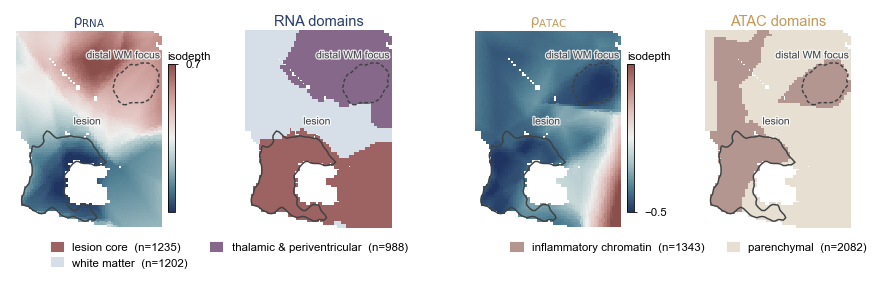

In [9]:
def region_contours(ax, lw=0.7):
    """outline of each focus: spots rasterised on the DBiT grid, holes filled, largest piece only, smoothed, contoured at 0.5"""
    from scipy.ndimage import binary_fill_holes, binary_closing, gaussian_filter, label
    ix = np.round((xy - xy.min(0)) / pitch).astype(int); n = ix.max(0) + 3
    gx = xy[:, 0].min() + (np.arange(n[0]) - 1) * pitch; gy = xy[:, 1].min() + (np.arange(n[1]) - 1) * pitch
    for r_, ls in (("lesion", "-"), ("distal WM focus", (0, (2.5, 1.5)))):
        M = np.zeros(n, bool); m = region == r_; M[ix[m, 0] + 1, ix[m, 1] + 1] = True
        M = binary_fill_holes(binary_closing(M, iterations=2))
        cc_, ncc = label(M)
        if ncc > 1:
            M = cc_ == np.bincount(cc_.ravel())[1:].argmax() + 1
        ax.contour(gx, gy, gaussian_filter(M.astype(float), 0.8).T, levels=[0.5], colors=[INK], linewidths=lw, linestyles=[ls])
        i_, j_ = np.nonzero(M)
        x_ = min(gx[i_].mean() + 0.3 * np.ptp(xy[:, 0]), xy[:, 0].max())
        ax.text(x_, gy[j_].max() + 1.5 * pitch, r_, fontsize=5, ha="right", va="bottom", color=INK,
                path_effects=[pe.withStroke(linewidth=1.2, foreground="white", alpha=0.85)], zorder=6)

def cbar(ax, sc, label, ticks=None):
    cb = ax.figure.colorbar(sc, cax=ax.inset_axes([1.03, 0.08, 0.05, 0.75]), ticks=ticks)
    cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    cb.ax.set_title(label, fontsize=5.5, pad=2, loc="left")

fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.2), gridspec_kw=dict(wspace=0.55))
for j, m in enumerate(modalities):
    d = D[m]; lo_, hi_ = np.percentile(d, [1, 99])
    sc = saturn.plotting.spatial(axs[2 * j], xy, d, cmap=CMAP["score"], vmin=lo_, vmax=hi_)
    cbar(axs[2 * j], sc, "isodepth", ticks=[round(lo_, 1), round(hi_, 1)])
    axs[2 * j].set_title(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m], fontsize=7, pad=2)
    saturn.plotting.spatial(axs[2 * j + 1], xy, LAB[m], discrete=True, colors=dict(enumerate(COLS[m])))
    axs[2 * j + 1].set_title(f"{m} domains", color=MODALITY[m], fontsize=7, pad=2)
    for a in axs[2 * j:2 * j + 2]:
        region_contours(a)
    ks = sorted(NAMES[m], key=lambda k: np.median(d[LAB[m] == k]))
    axs[2 * j + 1].legend(handles=[Patch(color=COLS[m][k]) for k in ks], fontsize=5.5, handlelength=1, loc="upper center",
                          labels=[f"{NAMES[m][k]}  (n={(LAB[m] == k).sum()})" for k in ks], bbox_to_anchor=(-0.1, -0.02), ncol=2)
plt.show()

## Fig. 2e: position of the two lesions along each isodepth

Each axis is turned into a percentile rank, oriented so that the injection lesion sits at the low end. Points are spots (600 of the
other spots are drawn) and black lines are medians. AUC compares the injection lesion with the distal WM focus (two-sided
Mann-Whitney U test).

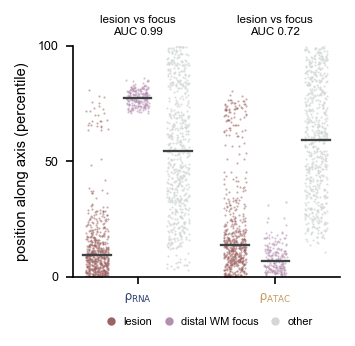

,axis,AUC,p,median pct lesion,median pct distal WM focus,median pct other
0,RNA,0.995,9.20e-100,9.285,77.387,54.307
1,ATAC,0.723,1.31e-21,13.898,6.905,59.066


In [10]:
rng = np.random.default_rng(1)
order = ["lesion", "distal WM focus", "other"]
fig, ax = plt.subplots(figsize=(2.3, 2.0))
rows = []
for g, m in enumerate(modalities):
    v = D[m] if np.median(D[m][region == "lesion"]) <= np.median(D[m]) else -D[m]
    pr = (np.argsort(np.argsort(v)) + 0.5) / len(v) * 100
    for i, r_ in enumerate(order):
        y = pr[region == r_]
        if r_ == "other":
            y = rng.choice(y, 600, replace=False)
        ax.scatter(g * 3.4 + i + rng.uniform(-0.28, 0.28, len(y)), y, s=1.0, lw=0, color=REGION[r_],
                   alpha=0.55 if r_ != "other" else 0.8, rasterized=True)
        mm = np.median(pr[region == r_])
        ax.plot([g * 3.4 + i - 0.34, g * 3.4 + i + 0.34], [mm, mm], color=INK, lw=1.1)
    a_, b_ = v[region == "lesion"], v[region == "distal WM focus"]
    u = mannwhitneyu(a_, b_)
    auc = max(u.statistic / (len(a_) * len(b_)), 1 - u.statistic / (len(a_) * len(b_)))
    rows.append(dict(axis=m, AUC=auc, p=u.pvalue, **{f"median pct {r_}": np.median(pr[region == r_]) for r_ in order}))
    ax.text(g * 3.4 + 1, 104, f"lesion vs focus\nAUC {auc:.2f}", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks([1, 4.4]); ax.set_xticklabels(["ρ$_{\\mathrm{RNA}}$", "ρ$_{\\mathrm{ATAC}}$"])
for tl, m in zip(ax.get_xticklabels(), modalities):
    tl.set_color(MODALITY[m])
ax.set_ylim(0, 100); ax.set_yticks([0, 50, 100]); ax.set_ylabel("position along axis (percentile)"); ax.set_xlim(-0.6, 6.0)
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color=REGION[r]) for r in order], labels=order, fontsize=5.3,
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, handletextpad=0.1, columnspacing=0.5)
plt.show()
t = pd.DataFrame(rows)
t.round(3).assign(p=t.p.map("{:.2e}".format))

## Fig. 2f-i: feature functions along the own axis

Each feature is fitted per domain by GASTON's Poisson regression with the likelihood-ratio gate at p < 0.1
(`saturn.piecewise.fit_poisson`). Each panel shows the measured log CP10k per spot, the fitted function at every spot, and the fitted
function along the isodepth: points are binned rates (30 equal-width bins of the axis for RNA, 20 for ATAC) coloured by domain, lines
are the per-domain fits and dotted lines mark domain boundaries. R² is computed on the rate scale against the binned values.

In [11]:
A = sp.csr_matrix(atac.X)[idx]
peaks = np.array(atac.var_names.astype(str))
LIB = {"RNA": np.asarray(X.sum(1)).ravel().clip(1), "ATAC": np.asarray(A.sum(1)).ravel().clip(1)}
MAT, FEATNAMES, NBIN = {"RNA": X.tocsc(), "ATAC": A.tocsc()}, {"RNA": genes, "ATAC": peaks}, {"RNA": 30, "ATAC": 20}

def along(ax, m, d, lab, bx, by, blab, curve, ylabel):
    """bin means in domain colours and the fitted function per domain along the own axis"""
    for k in range(lab.max() + 1):
        ax.scatter(bx[blab == k], by[blab == k], s=6, color=COLS[m][k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.linspace(d[lab == k].min(), d[lab == k].max(), 20)
        ax.plot(xs, curve(k, xs), color=COLS[m][k], lw=1.3, zorder=2)
    for b in sorted(d[lab == k].max() for k in range(lab.max() + 1))[:-1]:
        ax.axvline(b, color=GRID, lw=0.4, ls=(0, (2, 2)), zorder=1)
    ax.set_xlabel(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m], labelpad=1)
    ax.set_ylabel(ylabel, labelpad=1); ax.tick_params(labelsize=5.5, pad=1)


def feature_panel(m, feat, title, sub):
    """one feature: measured log CP10k per spot | fitted function at every spot | binned rate and fitted function along the own axis"""
    d, lab, lib = D[m], LAB[m], LIB[m]
    c = MAT[m][:, int(np.where(FEATNAMES[m] == feat)[0][0])].toarray().ravel().astype(float)
    sl, it = (v[0] for v in pw.fit_poisson(c[:, None], lib, lab, d))
    r2f, db, ob, _, lb = pw.binned_r2(c, d, lab, sl, it, NBIN[m], lib=lib, link="log")
    v = np.log1p(c / lib * 1e4)
    fit_spot = np.log1p(np.exp(it[lab] + sl[lab] * d) * 1e4)
    lo_, hi_ = np.percentile(np.r_[v, fit_spot], [2, 99])
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(3.6, 1.45), gridspec_kw=dict(wspace=0.75, width_ratios=[1, 1, 1.05]))
    saturn.plotting.spatial(a1, xy, v, cmap=CMAP["expression"], vmin=lo_, vmax=hi_)
    sc = saturn.plotting.spatial(a2, xy, fit_spot, cmap=CMAP["expression"], vmin=lo_, vmax=hi_)
    cbar(a2, sc, "log\nCP10k")
    a1.set_title(f"{title}\n{sub}", fontsize=6.2, pad=2, color=MODALITY[m], loc="left")
    a1.text(0.5, -0.04, "measured", transform=a1.transAxes, ha="center", va="top", fontsize=5.5)
    a2.text(0.5, -0.04, "fitted function", transform=a2.transAxes, ha="center", va="top", fontsize=5.5)
    along(a3, m, d, lab, db, np.log1p(ob * 1e6), lb, lambda k, xs: np.log1p(np.exp(it[k] + sl[k] * xs) * 1e6), "log(CPM+1)")
    ns = int((np.abs(sl) > 1e-9).sum())
    a3.set_title(f"fitted function · R² {r2f:.2f}\n{ns}/{len(sl)} domains sloped", fontsize=5.8, pad=2)
    plt.show()
    return pd.DataFrame([dict(feature=title, modality=m, R2=round(r2f, 3), n_sloped=ns, counts=int(c.sum()))])

### Fig. 2f: Trem2 along rho_RNA

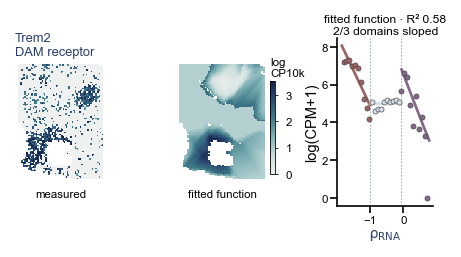

,feature,modality,R2,n_sloped,counts
0,Trem2,RNA,0.576,2,1061


In [12]:
feature_panel("RNA", "Trem2", "Trem2", "DAM receptor")

### Fig. 2g: Mbp along rho_RNA

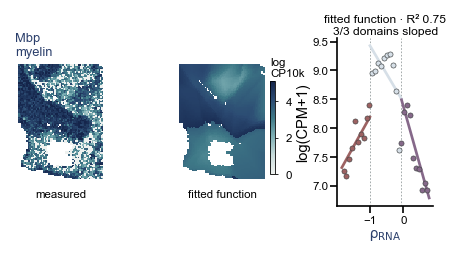

,feature,modality,R2,n_sloped,counts
0,Mbp,RNA,0.748,3,15544


In [13]:
feature_panel("RNA", "Mbp", "Mbp", "myelin")

### Fig. 2h: accessibility at the Tyrobp promoter along rho_ATAC

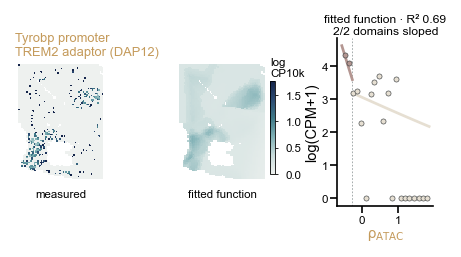

,feature,modality,R2,n_sloped,counts
0,Tyrobp promoter,ATAC,0.688,2,332


In [14]:
feature_panel("ATAC", "chr7:30412652-30413002", "Tyrobp promoter", "TREM2 adaptor (DAP12)")

### Fig. 2i: accessibility at the Spi1 +2 kb enhancer along rho_ATAC

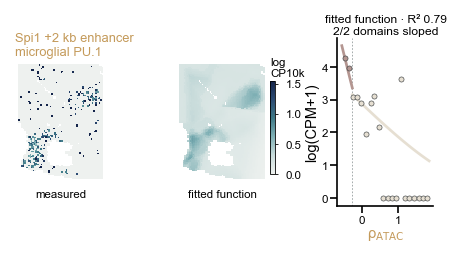

,feature,modality,R2,n_sloped,counts
0,Spi1 +2 kb enhancer,ATAC,0.794,2,297


In [15]:
feature_panel("ATAC", "chr2:91084599-91084795", "Spi1 +2 kb enhancer", "microglial PU.1")

## Fig. 2j: inflammatory program genes on rho_RNA and rho_ATAC

R² of the fitted function along rho_RNA and along rho_ATAC for every inflammatory program gene (DAM, homeostatic microglia, acute
IFN/NF-kB, complement and astrocyte) with at least 50 counts. Each gene is fitted along each axis in 25 equal-width bins by a Poisson
regression with a log-library offset and one hinge (linear term plus max(0, rho - b)), with the breakpoint b chosen among 10
quantiles of the bin centres by the deviance R². Points are genes, coloured by the axis with the higher R². One-sided paired Wilcoxon
signed-rank test.

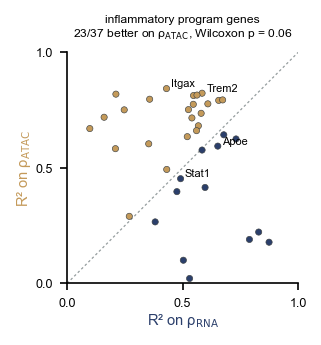

,gene,R2_dRNA,R2_dATAC
0,Itgax,0.430,0.843
1,Trem2,0.584,0.823
2,Cst7,0.211,0.819
3,Siglech,0.562,0.815
4,Ctsz,0.547,0.813
5,Ccl6,0.357,0.797
6,C1qc,0.673,0.794
7,C1qb,0.656,0.792
8,C1qa,0.609,0.777
9,Lyz2,0.546,0.775


In [16]:
INFL = ("Trem2 Tyrobp Apoe Cst7 Lpl Itgax Clec7a Cd9 Cd63 Cd74 Ctsb Ctsd Ctsl Ctsz Spp1 Gpnmb Igf1 Fth1 Lgals3 Axl Lyz2 Cybb Timp2 Csf1 Ccl6 "
        "P2ry12 P2ry13 Cx3cr1 Tmem119 Selplg Siglech Tnf Il1b Il6 Ccl2 Ccl3 Ccl4 Cxcl10 Nfkb1 Stat1 Irf7 Isg15 Ifit1 Ifit3 B2m "
        "C1qa C1qb C1qc C3 C4b Serpina3n Gfap").split()

def hinge_poisson_r2(cnt, expo, d, bp, n_iter=25):
    """deviance R² of a Poisson regression of binned counts on [1, d, max(0, d - bp)] with a log-exposure offset (IRLS)"""
    Xd = np.c_[np.ones(len(cnt)), d, np.maximum(0.0, d - bp)]
    off = np.log(np.maximum(expo, 1))
    beta = np.zeros(3); beta[0] = np.log(max(cnt.sum(), 1) / max(expo.sum(), 1))
    for _ in range(n_iter):
        eta = Xd @ beta + off
        mu = np.exp(np.clip(eta, -30, 30)); W = np.maximum(mu, 1e-8)
        new = np.linalg.lstsq(Xd * W[:, None], (eta - off + (cnt - mu) / W) * W, rcond=None)[0]
        if not np.all(np.isfinite(new)):
            break
        done = np.max(np.abs(new - beta)) < 1e-6
        beta = new
        if done:
            break
    mu = np.exp(np.clip(Xd @ beta + off, -30, 30))
    mu0 = np.maximum(expo * cnt.sum() / max(expo.sum(), 1), 1e-9)
    dev = lambda m_: 2 * np.sum(np.where(cnt > 0, cnt * np.log(np.maximum(cnt, 1e-9) / m_), 0) - (cnt - m_))
    return 1 - dev(mu) / max(dev(mu0), 1e-9)

def best_r2(cnt, d, lib, nb=25):
    bi, cen, kp = saturn.domains.isodepth_bins(d, nb)
    yb = np.array([cnt[bi == b].sum() for b in kp]); eb = np.array([lib[bi == b].sum() for b in kp])
    return max(hinge_poisson_r2(yb, eb, cen, bp) for bp in np.quantile(cen, np.linspace(0.2, 0.8, 10)))

tg = np.asarray(X.sum(0)).ravel().astype(float)
gidx = {g: i for i, g in enumerate(genes)}
Xc = X.tocsc()
rows = []
for g in INFL:
    if g in gidx and tg[gidx[g]] >= 50:
        c = Xc[:, gidx[g]].toarray().ravel().astype(float)
        rows.append(dict(gene=g, R2_dRNA=round(best_r2(c, d_R, LIB["RNA"]), 3), R2_dATAC=round(best_r2(c, d_A, LIB["RNA"]), 3)))
infl = pd.DataFrame(rows)
k_better = int((infl.R2_dATAC > infl.R2_dRNA).sum())
p_w = wilcoxon(infl.R2_dATAC, infl.R2_dRNA, alternative="greater").pvalue

fig, ax = plt.subplots(figsize=(2.0, 2.0))
ax.scatter(infl.R2_dRNA, infl.R2_dATAC, s=9, c=np.where(infl.R2_dATAC > infl.R2_dRNA, C_ATAC, C_RNA), lw=0.3, edgecolor=INK, zorder=3)
ax.plot([0, 1], [0, 1], color=GRID, lw=0.6, ls=(0, (2, 2)), zorder=1)
for g in ["Itgax", "Trem2", "Apoe", "Stat1"]:
    r_ = infl[infl.gene == g]
    ax.annotate(g, (r_.R2_dRNA.iloc[0], r_.R2_dATAC.iloc[0]), fontsize=5.3, xytext=(2, 1), textcoords="offset points", style="italic")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1]); ax.set_aspect("equal")
ax.set_xlabel("R² on ρ$_{\\mathrm{RNA}}$", color=C_RNA, labelpad=1); ax.set_ylabel("R² on ρ$_{\\mathrm{ATAC}}$", color=C_ATAC, labelpad=1)
ax.set_title(f"inflammatory program genes\n{k_better}/{len(infl)} better on ρ$_{{\\mathrm{{ATAC}}}}$, Wilcoxon p = {p_w:.2f}", fontsize=5.8, pad=7)
plt.show()
infl.sort_values("R2_dATAC", ascending=False).reset_index(drop=True)

## TF activity along the axes

chromVAR-style TF activity with isodepth bins in place of metacells (`saturn.tfactivity`). The 12,000 most-counted peaks are scanned
with JASPAR 2022 motifs of 26 TFs from five lineages, on both strands; a peak is a hit when its score is in the top 1% for that TF.
Each TF gets 50 background peak sets matched on GC content and accessibility. `rho_binned_activity` cuts rho_ATAC into 60
equal-count bins, computes the deviation z of each TF per bin and fits z as a per-domain linear function of the axis with the
Gaussian gate.

In [17]:
PANEL = {"OL": ["SOX10", "OLIG1", "OLIG2", "MYRF", "NKX2-2", "ZEB2"], "astrocyte": ["SOX9", "NFIA", "NFIB", "HES5", "LHX2", "ID3"],
         "microglia": ["IRF8", "MAFB", "MEF2C", "CEBPA", "SPI1", "KLF4"], "stress": ["ATF4", "DDIT3", "STAT3", "NFKB1"],
         "neuron": ["NEUROD1", "NEUROG2", "POU3F2", "POU3F3"]}
lineage = {t: k for k, v in PANEL.items() for t in v}
TA = saturn.tfactivity
FASTA = WORK / "mm10.fa"

keep = np.sort(np.argsort(-np.asarray(A.sum(0)).ravel().astype(float))[:12000])
pwm = TA.jaspar_pwms(list(lineage))
seqs, valid = TA.peak_sequences(FASTA, peaks, keep)
hits, tfs = TA.scan_motifs(seqs, pwm, q=0.99)
A_m = A[:, valid]
BG = TA.background_sets(TA.peak_gc(FASTA, peaks, valid), np.asarray(A_m.sum(0)).ravel().astype(float), hits)
print(f"{len(pwm)} of {len(lineage)} TFs have a JASPAR motif; {hits.shape[0]} peaks scanned; median {int(np.median(hits.sum(0)))} hits per TF")

tf_fits, tf_bins, _ = TA.rho_binned_activity(A_m, d_A, lab_A, hits, tfs, BG)
tf_fits.insert(1, "lineage", tf_fits.tf.map(lineage))
tf_fits.sort_values("R2", ascending=False).head(8)

23 of 26 TFs have a JASPAR motif; 12000 peaks scanned; median 120 hits per TF


,tf,lineage,R2,n_sloped,slopes,z_range
13,SPI1,microglia,0.841,2,"[-34.815, -1.71]",11.03
12,CEBPA,microglia,0.768,2,"[-34.495, -1.292]",11.69
10,MAFB,microglia,0.698,2,"[-21.363, -0.549]",7.49
22,POU3F3,neuron,0.674,1,"[17.042, 0.0]",7.52
21,POU3F2,neuron,0.643,1,"[17.076, 0.0]",7.37
8,LHX2,astrocyte,0.564,2,"[17.539, 0.798]",6.25
9,IRF8,microglia,0.559,2,"[-14.865, -1.115]",5.22
5,NFIA,astrocyte,0.507,2,"[-6.726, -1.166]",4.73


## Fig. 2k: TF activity along rho_ATAC

Activity (chromVAR-style deviation z) of the 20 TFs with R² of at least 0.15 along rho_ATAC in 60 equal-count bins, observed and
fitted, grouped by lineage and ordered by where they peak. The strip marks the ATAC domains; R² of the fitted function is at the right
(bold at 0.5 or above).

left to the supplementary heatmap (R² < 0.15): ['ATF4', 'DDIT3', 'NKX2-2']


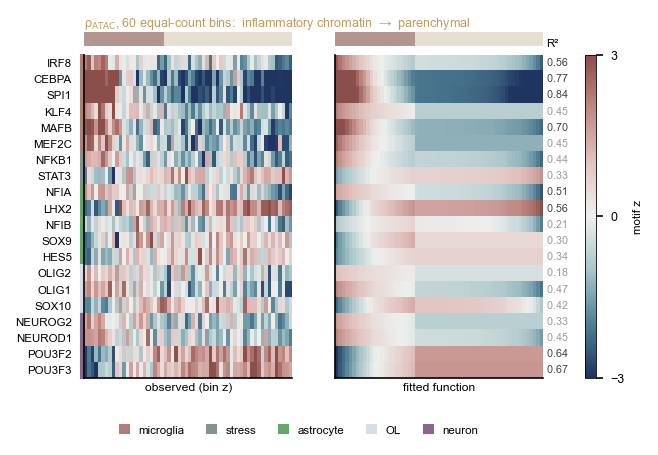

In [18]:
LINEAGE_ORDER = ["microglia", "stress", "astrocyte", "OL", "neuron"]
f_ = tf_fits.set_index("tf")
Z = tf_bins.pivot(index="tf", columns="bin", values="z")
Fz = tf_bins.pivot(index="tf", columns="bin", values="fitted")
rho_b = tf_bins.groupby("bin").rho.mean().loc[Z.columns].values
dom_b = tf_bins.groupby("bin").domain.agg(lambda s: s.mode().iloc[0]).loc[Z.columns].values
rows_tf = []
for L in LINEAGE_ORDER:
    rows_tf += sorted([t for t in Z.index if f_.loc[t, "lineage"] == L and f_.loc[t, "R2"] >= 0.15],
                      key=lambda t: rho_b[np.argmax(Z.loc[t].values)])
print("TFs not drawn in Fig. 2k (R² < 0.15):", [t for t in Z.index if t not in rows_tf])

fig, axs = plt.subplots(2, 3, figsize=(4.4, 3.0), gridspec_kw=dict(height_ratios=[0.045, 1], width_ratios=[1, 1, 0.05], hspace=0.05, wspace=0.3))
for j, (M_, xl) in enumerate(((Z, "observed (bin z)"), (Fz, "fitted function"))):
    im = axs[1, j].imshow(M_.loc[rows_tf, Z.columns].values, aspect="auto", cmap=CMAP["score"], vmin=-3, vmax=3, interpolation="nearest")
    axs[1, j].set_xticks([]); axs[1, j].set_xlabel(xl, fontsize=5.8, labelpad=2)
    axs[0, j].imshow(dom_b[None, :], aspect="auto", cmap=ListedColormap(COLS["ATAC"]), vmin=-0.5, vmax=len(COLS["ATAC"]) - 0.5,
                     interpolation="nearest")
    axs[0, j].set_axis_off()
axs[1, 1].set_yticks([])
axs[1, 0].set_yticks(range(len(rows_tf))); axs[1, 0].set_yticklabels(rows_tf, fontsize=5.5); axs[1, 0].tick_params(axis="y", length=0, pad=6)
for i, t in enumerate(rows_tf):
    axs[1, 0].add_patch(Rectangle((-1.5, i - 0.5), 1.0, 1, color=LINEAGE[f_.loc[t, "lineage"]], clip_on=False))
    r2t = f_.loc[t, "R2"]
    axs[1, 1].text(Z.shape[1] - 0.2, i, f" {r2t:.2f}", fontsize=5.2, va="center", ha="left",
                   fontweight="bold" if r2t >= 0.5 else "normal", color=INK if r2t >= 0.5 else GRID)
axs[1, 1].text(Z.shape[1] + 0.3, -0.9, "R²", fontsize=5.5, ha="left", va="bottom")
ends = [NAMES["ATAC"][int(dom_b[0])], NAMES["ATAC"][int(dom_b[-1])]]
axs[0, 0].set_title(f"ρ$_{{\\mathrm{{ATAC}}}}$, 60 equal-count bins:  {ends[0]}  →  {ends[1]}", color=C_ATAC, fontsize=6, pad=2, loc="left")
axs[0, 2].set_axis_off()
cb = fig.colorbar(im, cax=axs[1, 2], ticks=[-3, 0, 3]); cb.outline.set_linewidth(0.4); cb.set_label("motif z", fontsize=5.5)
fig.legend(handles=[Patch(color=LINEAGE[L]) for L in LINEAGE_ORDER], labels=LINEAGE_ORDER, ncol=5, fontsize=5.5, loc="lower center",
           bbox_to_anchor=(0.45, -0.04), handlelength=0.8)
plt.show()

## Fig. 2l: per-spot activity of SPI1 and POU3F3

The same deviation per spot (`deviations_matched` on depth-normalised log accessibility, n = 3,425 spots): measured values, the
per-domain linear function of rho_ATAC fitted at spot level with the same domains and gate, and the fitted function along rho_ATAC
(points are means of 30 equal-count groups of spots); R² is computed per spot.

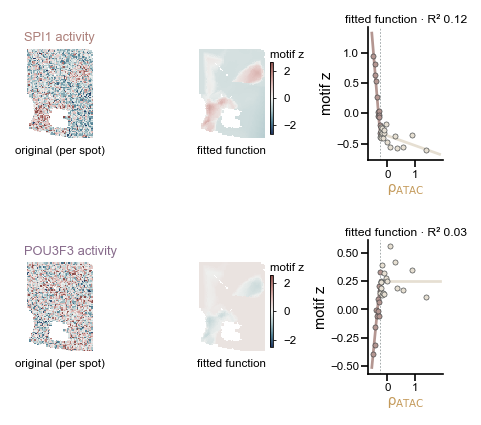

In [19]:
Z_spot = TA.deviations_matched(TA.log_accessibility(A_m, dtype=np.float32), hits, BG)

fig, axs = plt.subplots(2, 3, figsize=(3.6, 3.0), gridspec_kw=dict(wspace=1.4, hspace=0.6, width_ratios=[1, 1, 1.05]))
for r, (tf, col) in enumerate((("SPI1", LINEAGE["microglia"]), ("POU3F3", LINEAGE["neuron"]))):
    v = Z_spot[:, tfs.index(tf)].astype(float)
    sl, it = (q[0] for q in pw.fit_gauss(v[:, None], lab_A, d_A))
    fit_spot = it[lab_A] + sl[lab_A] * d_A
    r2t = 1 - ((v - fit_spot) ** 2).sum() / ((v - v.mean()) ** 2).sum()
    lim = np.percentile(np.abs(v), 98)
    saturn.plotting.spatial(axs[r, 0], xy, v, cmap=CMAP["score"], vmin=-lim, vmax=lim)
    sc = saturn.plotting.spatial(axs[r, 1], xy, fit_spot, cmap=CMAP["score"], vmin=-lim, vmax=lim)
    cbar(axs[r, 1], sc, "motif z")
    axs[r, 0].set_title(f"{tf} activity", fontsize=6.2, pad=2, loc="left", color=col)
    axs[r, 0].text(0.5, -0.04, "original (per spot)", transform=axs[r, 0].transAxes, ha="center", va="top", fontsize=5.5)
    axs[r, 1].text(0.5, -0.04, "fitted function", transform=axs[r, 1].transAxes, ha="center", va="top", fontsize=5.5)
    q = np.array_split(np.argsort(d_A), 30)
    along(axs[r, 2], "ATAC", d_A, lab_A, np.array([d_A[g].mean() for g in q]), np.array([v[g].mean() for g in q]),
          np.array([np.bincount(lab_A[g], minlength=k_A).argmax() for g in q]), lambda k, xs: it[k] + sl[k] * xs, "motif z")
    axs[r, 2].set_title(f"fitted function · R² {r2t:.2f}", fontsize=5.8, pad=2)
plt.show()

## Genes and their cis peaks

Genes: the 1,500 most-counted plus programme genes with at least 100 counts. `cis_pairs` takes, for each gene, up to 25 peaks within
1 Mb of the TSS and, as a control, up to 10 peaks at least 5 Mb away on the same chromosome. Genes and peaks are k-NN smoothed,
z-scored log1p CP10k (`smoothed_logcpm`, 15 neighbours). `function_pairs` fits gene and peak per domain along one axis and keeps the
pairs and domains where both slopes pass the gate; `concordant` records whether the two slopes have the same sign.

In [20]:
programme = ("Trem2 Tyrobp Csf1r Cx3cr1 P2ry12 Tmem119 Irf8 Spi1 C1qa C1qb C1qc Ctss Hexb Fcrls Inpp5d Mertk Lgals3bp Apoe Cst7 Itgax Cd68 Aif1 "
             "Lyz2 Mpeg1 Laptm5 Ptprc Cd9 Man2b1 Ctsb Ctsd Ctsl Gpnmb Fth1 Spp1 Marcks Lrmda Ly86 Cd83 Syk Plek Dock8 Zeb2 Mbp Plp1 Mog Mag Mobp Cnp "
             "Cldn11 Sox10 Olig1 Olig2 Mal Ugt8a Aspa Trf Apod Ptgds Opalin Ermn Gfap Aqp4 Slc1a2 Slc1a3 Aldh1l1 S100b Sox9 Nfia Clu Vim Snap25 Syt1 "
             "Rbfox3 Nrgn Camk2a Slc17a7 Gad1 Gad2 Syp Nefl").split()
CS = saturn.cis
tp = np.asarray(A.sum(0)).ravel().astype(float)
kg = list(np.argsort(-tg)[:1500])
kg = np.array(kg + [gidx[g] for g in programme if g in gidx and tg[gidx[g]] >= 100 and gidx[g] not in set(kg)])

tss = CS.tss_table(WORK / "gencode.vM25.primary_chr.annotation.gtf")
cis, dist = CS.cis_pairs(kg, genes, peaks, tp, tss, distal_min=5_000_000)
need = np.unique(np.concatenate([v for v in list(cis.values()) + list(dist.values()) if len(v)]))
xy32 = xy.astype(np.float32)
G, Pk = CS.smoothed_logcpm(X, kg, xy32, 15), CS.smoothed_logcpm(A, need, xy32, 15)
gpos, ppos = {v: i for i, v in enumerate(kg)}, {v: i for i, v in enumerate(need)}
_, pmid = CS.peak_positions(peaks)

def pair_list(axis):
    return [(gpos[g], ppos[s], dict(axis=axis, kind=kind, gene=genes[g], peak=peaks[s], kb=(pmid[s] - tss[genes[g]][1]) / 1e3))
            for g, pk in cis.items() for kind, sel in (("cis", pk), ("distal", dist.get(g, np.array([], int)))) for s in sel]

pairs = pd.concat([CS.function_pairs(G, Pk, D[m], LAB[m], pair_list(m)) for m in modalities], ignore_index=True)
print(f"{len(cis)} genes with cis peaks, {len(need)} distinct peaks, {len(pairs)} gene-peak-domain rows")

1499 genes with cis peaks, 16566 distinct peaks, 175210 gene-peak-domain rows


## Fig. 2m: near minus distal concordance, Saturn and SEACells

For the same gene-peak-domain triples, the share of concordant pairs within 25 kb of the TSS minus the share among distal (>5 Mb)
pairs. Saturn: pairs where gene and peak both keep a slope in the domain (computed above). SEACells metacells on ATAC LSI and on
RNA PCA, keeping gene-peak correlations with p < 0.05 (SEACells, separate environment, `reproducibility/paper/scripts/lpc10_seacells_cis_benchmark.py`; read from
`published/`). Two-sided chi-squared test (* p < 0.05, *** p < 0.001).

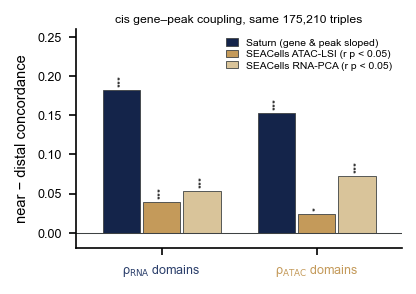

,method,axis,near,distal,gap,n_near,n_distal,p
0,Saturn,RNA,0.581,0.399,0.182,5593,34421,2.30e-144
1,SEACells-LSI,RNA,0.915,0.877,0.039,994,9052,4.49e-04
2,SEACells-PCA,RNA,0.893,0.841,0.053,873,5183,7.05e-05
3,Saturn,ATAC,0.541,0.388,0.153,3860,22892,3.13e-71
4,SEACells-LSI,ATAC,0.940,0.916,0.024,756,5988,2.63e-02
5,SEACells-PCA,ATAC,0.904,0.831,0.073,623,3855,4.95e-06


In [21]:
def stars(p):
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "n.s."

def gap(s):
    near, far = s[(s.kind == "cis") & (s.kb.abs() < 25)].concordant, s[s.kind == "distal"].concordant
    tab = [[near.sum(), len(near) - near.sum()], [far.sum(), len(far) - far.sum()]]
    return dict(near=near.mean(), distal=far.mean(), gap=near.mean() - far.mean(), n_near=len(near), n_distal=len(far), p=chi2_contingency(tab)[1])

SC = pd.read_csv(PUB / "lpc10_fov_seacells/summary.csv")
METH = [("Saturn", SATURN, "Saturn (gene & peak sloped)"), ("SEACells-LSI", ANCHOR["ochre"], "SEACells ATAC-LSI (r p < 0.05)"),
        ("SEACells-PCA", ANCHOR["sand"], "SEACells RNA-PCA (r p < 0.05)")]
rows = []
for m in modalities:
    rows.append(dict(method="Saturn", axis=m, **gap(pairs[pairs.axis == m])))
    for k in ("SEACells-LSI", "SEACells-PCA"):
        r = SC[(SC.method == k) & (SC.axis == m) & (SC["filter"] == "p<0.05")].iloc[0]
        rows.append(dict(method=k, axis=m, near=r.near, distal=r.distal, gap=r.gap, n_near=r.n_near, n_distal=r.n_distal, p=r.p))
gaps = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(2.8, 1.9))
for j, m in enumerate(modalities):
    for i, (k, col, _) in enumerate(METH):
        r = gaps[(gaps.method == k) & (gaps.axis == m)].iloc[0]
        ax.bar(j + (i - 1) * 0.26, r.gap, 0.24, color=col, lw=0.4, edgecolor=INK)
        ax.text(j + (i - 1) * 0.26, max(r.gap, 0) + 0.004, stars(r.p), ha="center", va="bottom", fontsize=5, rotation=90)
ax.axhline(0, color=INK, lw=0.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["ρ$_{\\mathrm{RNA}}$ domains", "ρ$_{\\mathrm{ATAC}}$ domains"])
for t, m in zip(ax.get_xticklabels(), modalities):
    t.set_color(MODALITY[m])
ax.set_ylabel("near − distal concordance"); ax.set_ylim(-0.02, 0.26); ax.set_xlim(-0.55, 1.55)
ax.legend(handles=[Patch(fc=c, ec=INK, lw=0.4, label=l) for _, c, l in METH], fontsize=5, loc="upper right", handlelength=1.2, labelspacing=0.2)
ax.set_title(f"cis gene–peak coupling, same {len(pairs):,} triples", fontsize=5.8, pad=3)
plt.show()
gaps.round(3).assign(p=gaps.p.map("{:.2e}".format))

## Fig. 2n: near minus distal concordance per domain

The same difference per domain, for the three domains of rho_RNA and the two domains of rho_ATAC; SEACells values with the same
p < 0.05 filter, assigned to the Saturn domains (read from `published/`).

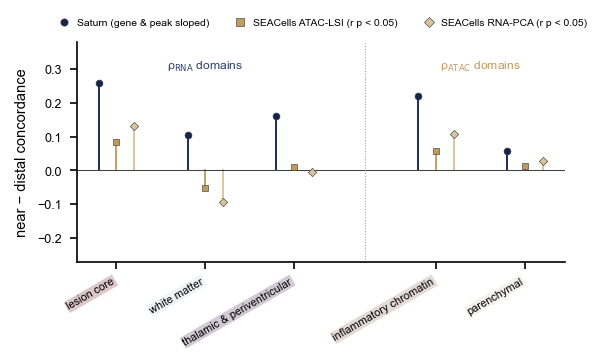

,axis,domain,Saturn,SEACells-LSI,SEACells-PCA
0,RNA,lesion core,0.259,0.083,0.133
1,RNA,white matter,0.106,-0.053,-0.094
2,RNA,thalamic & periventricular,0.160,0.009,-0.005
3,ATAC,inflammatory chromatin,0.220,0.057,0.108
4,ATAC,parenchymal,0.058,0.012,0.028


In [22]:
SD = pd.read_csv(PUB / "lpc10_fov_seacells/per_domain.csv")
MK = {"Saturn": "o", "SEACells-LSI": "s", "SEACells-PCA": "D"}
fig, ax = plt.subplots(figsize=(4.2, 1.9))
x, xs, labs, cen, rows = 0, [], [], {}, []
for m in modalities:
    x0 = x
    for k_dom in sorted(NAMES[m]):
        dname = NAMES[m][k_dom]
        vals = {"Saturn": gap(pairs[(pairs.axis == m) & (pairs.domain == k_dom)])["gap"]}
        for k in ("SEACells-LSI", "SEACells-PCA"):
            r = SD[(SD.method == f"{k} (p<0.05)") & (SD.axis == m) & (SD.domain == dname)]
            vals[k] = float(r.gap.iloc[0]) if len(r) else np.nan
        for (k, col, _), dx in zip(METH, (-0.2, 0, 0.2)):
            if np.isfinite(vals[k]):
                ax.plot([x + dx, x + dx], [0, vals[k]], color=col, lw=0.9, zorder=2)
                ax.scatter(x + dx, vals[k], s=11 if k == "Saturn" else 8, marker=MK[k], color=col, lw=0.3, edgecolor=INK, zorder=3)
        rows.append(dict(axis=m, domain=dname, **{k: round(v, 3) for k, v in vals.items()}))
        xs.append(x); labs.append(dname); x += 1
    cen[m] = (x0 + x - 1) / 2; x += 0.6
ax.axhline(0, color=INK, lw=0.5)
ax.axvline(len(NAMES["RNA"]) - 0.2, color=GRID, lw=0.5, ls=":")
ax.set_xticks(xs); ax.set_xticklabels(labs, rotation=30, ha="right", fontsize=5.3)
for t, (m, k_dom) in zip(ax.get_xticklabels(), [(m, k) for m in modalities for k in sorted(NAMES[m])]):
    t.set_bbox(dict(fc=COLS[m][k_dom], ec="none", alpha=0.35, pad=0.6))
for m in modalities:
    ax.text(cen[m], 0.3, f"ρ$_{{\\mathrm{{{m}}}}}$ domains", color=MODALITY[m], ha="center", fontsize=5.8)
ax.set_ylim(-0.27, 0.38); ax.set_ylabel("near − distal concordance")
ax.legend(handles=[Line2D([], [], marker=MK[k], ls="", color=c, mec=INK, mew=0.3, ms=3.5, label=l) for k, c, l in METH],
          fontsize=5, loc="upper center", ncol=3, handletextpad=0.2, bbox_to_anchor=(0.5, 1.15))
plt.show()
pd.DataFrame(rows)